# Fixed vs. Varied Leiden Seed: Between-Run Clustering Comparison

## Purpose
Compare clustering evaluations from two batches while matching on the same parameter configuration (`n_neighbors`, `n_pcs`, `resolution`). The analysis checks whether the same cells are present, whether cluster structure and recorded metrics agree, and whether the cell-level partitions are identical.

- **Batch A — fixed seeds:** LLM seed 42; Leiden seed 42.
- **Batch B — varied Leiden seed:** LLM seed 42; Leiden seeds vary by run.
- **Dataset:** PBMC3k, 2,638 cells (as used in the experiment).

**Interpretation note:** a matched parameter configuration does not necessarily occur at the same iteration in both runs. The cross-batch merge compares every evaluation pair that shares the parameter configuration, so pairs are not necessarily independent observations.

## 1. Imports and input paths

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

batch_a_analysis_dir = (
    Path.cwd() / "experiments"
    / "llm_seed42_agent_repeatability_20261018_222712_094535"
    / "new_analysis_k9"
)
batch_b_analysis_dir = (
    Path.cwd() / "experiments"
    / "llm_seed42_agent_varied_leiden_20261019_104037_105953"
    / "new_analysis_k9"
)

batch_a_dir = batch_a_analysis_dir.parent
batch_b_dir = batch_b_analysis_dir.parent

batch_a_trajectory = pd.read_csv(
    batch_a_analysis_dir / "new_iteration_trajectory_table.csv"
)
batch_b_trajectory = pd.read_csv(
    batch_b_analysis_dir / "new_iteration_trajectory_table.csv"
)

PARAMS = ["n_neighbors", "n_pcs", "resolution"]
LEIDEN_SEED_BY_RUN_B = {
    1: 1, 2: 2, 3: 3, 4: 7,
    5: 11, 6: 17, 7: 23, 8: 42,
}

# Normalize types so parameter matching is reliable.
for df in (batch_a_trajectory, batch_b_trajectory):
    df["run_index"] = df["run_index"].astype(int)
    df["iteration"] = df["iteration"].astype(int)
    df["n_neighbors"] = df["n_neighbors"].astype(int)
    df["n_pcs"] = df["n_pcs"].astype(int)
    df["resolution"] = df["resolution"].astype(float)

print(f"Batch A evaluations: {len(batch_a_trajectory)}")
print(f"Batch B evaluations: {len(batch_b_trajectory)}")

Batch A evaluations: 99
Batch B evaluations: 105


## 2. Identify shared parameter configurations

Configurations are matched by the three clustering parameters, not by iteration number. The counts below show how many distinct configurations each batch explored and how many are shared.

In [2]:
batch_a_configs = batch_a_trajectory[PARAMS].drop_duplicates()
batch_b_configs = batch_b_trajectory[PARAMS].drop_duplicates()
shared_configs = (
    batch_a_configs.merge(batch_b_configs, on=PARAMS, how="inner")
    .sort_values(PARAMS)
    .reset_index(drop=True)
)

print(f"Distinct configurations in Batch A: {len(batch_a_configs)}")
print(f"Distinct configurations in Batch B: {len(batch_b_configs)}")
print(f"Shared configurations: {len(shared_configs)}")

# Compact occurrence table: useful for understanding repeated configurations
# and why the number of matched evaluation pairs can exceed unique configs.
def count_configurations(df, name):
    return df.groupby(PARAMS).size().rename(f"{name}_occurrences")

configuration_counts = pd.concat([
    count_configurations(batch_a_trajectory, "batch_a"),
    count_configurations(batch_b_trajectory, "batch_b"),
], axis=1).fillna(0).astype(int).reset_index()
configuration_counts["shared_configuration"] = (
    (configuration_counts["batch_a_occurrences"] > 0)
    & (configuration_counts["batch_b_occurrences"] > 0)
)
configuration_counts["matched_pair_count"] = (
    configuration_counts["batch_a_occurrences"]
    * configuration_counts["batch_b_occurrences"]
)
configuration_counts = configuration_counts.sort_values(
    ["shared_configuration", "matched_pair_count"],
    ascending=[False, False]
).reset_index(drop=True)

print("Potential cross-batch evaluation pairs:", int(configuration_counts["matched_pair_count"].sum()))
display(configuration_counts.head(10))

Distinct configurations in Batch A: 82
Distinct configurations in Batch B: 78
Shared configurations: 22
Potential cross-batch evaluation pairs: 107


,n_neighbors,n_pcs,resolution,batch_a_occurrences,batch_b_occurrences,shared_configuration,matched_pair_count
0,15,30,1.0,8,8,True,64
1,20,30,1.0,4,2,True,8
2,15,30,0.8,2,3,True,6
3,20,30,0.8,3,1,True,3
4,15,12,0.9,1,2,True,2
5,20,15,0.8,1,2,True,2
6,25,30,1.0,2,1,True,2
7,30,12,0.8,1,2,True,2
8,30,15,0.8,1,2,True,2
9,30,20,0.8,1,2,True,2


## 3. Load cell-level labels safely

The filename includes the run index, Leiden seed, and iteration. Batch A uses seed 42; Batch B uses the seed assigned to each run. Cell IDs are used to align labels before computing partition agreement.

In [3]:
def load_iteration(run_dir, run_index, iteration, leiden_seed=42):
    run_tag = f"REPEAT_{int(run_index):02d}_LSEED_{int(leiden_seed):02d}"
    iter_tag = f"{run_tag}_ITER_{int(iteration):02d}"
    label_files = list(run_dir.glob(f"*{iter_tag}_labels.npy"))
    id_files = list(run_dir.glob(f"*{iter_tag}_cell_ids.npy"))

    if len(label_files) != 1 or len(id_files) != 1:
        raise FileNotFoundError(
            f"Expected one labels and one cell-ID file for {iter_tag}. "
            f"Labels found: {[p.name for p in label_files]}; "
            f"cell-ID files found: {[p.name for p in id_files]}"
        )

    labels = np.load(label_files[0], allow_pickle=True).ravel()
    cell_ids = np.load(id_files[0], allow_pickle=True).ravel()
    if len(labels) != len(cell_ids):
        raise ValueError(f"Label count differs from cell-ID count for {iter_tag}.")
    if pd.Index(cell_ids).has_duplicates:
        raise ValueError(f"Duplicate cell IDs found for {iter_tag}.")

    return pd.Series(labels, index=pd.Index(cell_ids, name="cell_id"))


def compare_clusterings(labels_a, labels_b):
    same_cells = (
        len(labels_a) == len(labels_b)
        and set(labels_a.index) == set(labels_b.index)
    )
    if not same_cells:
        raise ValueError("The two evaluations do not contain the same cell IDs.")

    # Align by cell ID rather than assuming array order is identical.
    labels_b = labels_b.reindex(labels_a.index)
    if labels_b.isna().any():
        raise ValueError("Missing labels after cell-ID alignment.")

    sizes_a = tuple(sorted(pd.Series(labels_a).value_counts().tolist(), reverse=True))
    sizes_b = tuple(sorted(pd.Series(labels_b).value_counts().tolist(), reverse=True))
    n_clusters_a = pd.Series(labels_a).nunique()
    n_clusters_b = pd.Series(labels_b).nunique()
    ari = adjusted_rand_score(labels_a, labels_b)
    nmi = normalized_mutual_info_score(labels_a, labels_b)

    return {
        "same_cell_ids": same_cells,
        "n_cells": len(labels_a),
        "clusters_from_labels_batch_a": n_clusters_a,
        "clusters_from_labels_batch_b": n_clusters_b,
        "same_cluster_count": n_clusters_a == n_clusters_b,
        "same_cluster_size_distribution": sizes_a == sizes_b,
        "ARI": ari,
        "NMI": nmi,
        "identical_partition": np.isclose(ari, 1.0) and np.isclose(nmi, 1.0),
        "cluster_sizes_a": sizes_a,
        "cluster_sizes_b": sizes_b,
    }

## 4. Match evaluations and compare partitions

Every evaluation in Batch A is paired with every evaluation in Batch B that has the same parameter configuration. ARI and NMI compare the actual cell assignments; recorded metrics are also checked using a strict numerical tolerance.

In [4]:
matched = batch_a_trajectory.merge(
    batch_b_trajectory,
    on=PARAMS,
    how="inner",
    suffixes=("_a", "_b"),
)
print(f"Matched evaluation pairs: {len(matched)}")

comparison_rows = []
for _, row in matched.iterrows():
    run_a = int(row["run_index_a"])
    run_b = int(row["run_index_b"])
    iteration_a = int(row["iteration_a"])
    iteration_b = int(row["iteration_b"])
    seed_b = LEIDEN_SEED_BY_RUN_B[run_b]

    labels_a = load_iteration(batch_a_dir, run_a, iteration_a, leiden_seed=42)
    labels_b = load_iteration(
        batch_b_dir, run_b, iteration_b, leiden_seed=seed_b
    )
    result = compare_clusterings(labels_a, labels_b)

    metrics_match = all(
        np.isclose(
            row[f"{metric}_a"], row[f"{metric}_b"],
            rtol=1e-10, atol=1e-12, equal_nan=True,
        )
        for metric in ["silhouette", "davies_bouldin", "wc_dispersion"]
    )

    comparison_rows.append({
        **{p: row[p] for p in PARAMS},
        "run_a": run_a,
        "leiden_seed_a": 42,
        "iteration_a": iteration_a,
        "run_b": run_b,
        "leiden_seed_b": seed_b,
        "iteration_b": iteration_b,
        "recorded_clusters_a": int(row["n_clusters_a"]),
        "recorded_clusters_b": int(row["n_clusters_b"]),
        **result,
        "metrics_match": metrics_match,
    })

comparison = pd.DataFrame(comparison_rows)
comparison["labels_batch_agree_with_recorded_counts"] = (
    (comparison["clusters_from_labels_batch_a"] == comparison["recorded_clusters_a"])
    & (comparison["clusters_from_labels_batch_b"] == comparison["recorded_clusters_b"])
)

print(f"Completed comparisons: {len(comparison)}")

Matched evaluation pairs: 107
Completed comparisons: 107


## 5. Summary of agreement checks

The percentages below describe **matched evaluation pairs**, not independent experiments. Repeated configurations can contribute multiple pairs.

In [5]:
checks = {
    "Same cell IDs": comparison["same_cell_ids"],
    "Same cluster count": comparison["same_cluster_count"],
    "Same cluster-size distribution": comparison["same_cluster_size_distribution"],
    "ARI = 1": np.isclose(comparison["ARI"], 1.0),
    "NMI = 1": np.isclose(comparison["NMI"], 1.0),
    "Recorded metrics match": comparison["metrics_match"],
}
summary = pd.DataFrame({
    "Check": list(checks),
    "Consistent pairs": [int(v.sum()) for v in checks.values()],
    "Total pairs": len(comparison),
})
summary["Percent consistent"] = (
    100 * summary["Consistent pairs"] / summary["Total pairs"]
).round(2)
display(summary)

,Check,Consistent pairs,Total pairs,Percent consistent
0,Same cell IDs,107,107,100.00
1,Same cluster count,92,107,85.98
2,Same cluster-size distribution,14,107,13.08
3,ARI = 1,14,107,13.08
4,NMI = 1,14,107,13.08
5,Recorded metrics match,14,107,13.08


## 6. Visualize the results

This plot summarizes the proportion of matched pairs passing each check. It is a compact overview; consult the table above for counts and denominators.

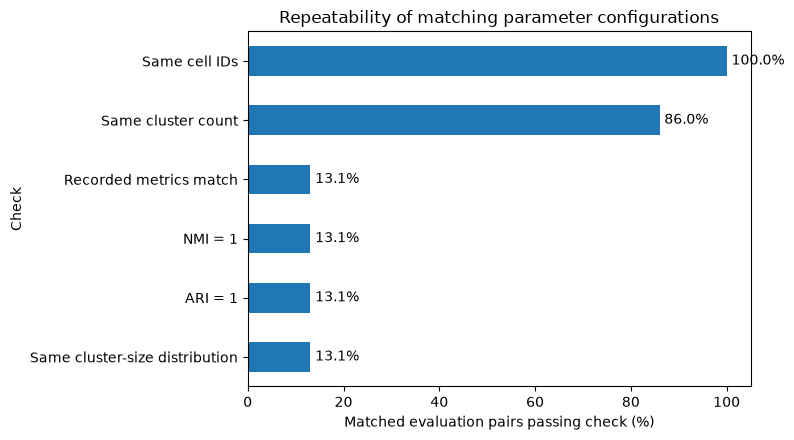

In [6]:
percentages = summary.set_index("Check")["Percent consistent"]
ax = percentages.sort_values().plot(
    kind="barh", figsize=(8, 4.5), xlim=(0, 105),
    xlabel="Matched evaluation pairs passing check (%)",
    title="Repeatability of matching parameter configurations",
)
for bar in ax.patches:
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center",
    )
plt.tight_layout()
plt.show()

## 7. Inspect exact matches

This focused audit table shows only pairs that passed all checks, rather than printing the full comparison table. The seed columns help distinguish same-seed from different-seed comparisons.

This audit identifies matched parameter configurations whose clustering results pass all consistency checks: identical cell IDs, matching cluster counts and sorted cluster-size distributions, ARI = 1.0, NMI = 1.0, matching recorded metrics, and agreement between recorded and label-derived cluster counts. Passing all checks indicates that the two partitions are identical, with matching evaluation metrics and metadata.

In [7]:
all_checks_pass = (
    comparison["same_cell_ids"]
    & comparison["same_cluster_count"]
    & comparison["same_cluster_size_distribution"]
    & np.isclose(comparison["ARI"], 1.0)
    & np.isclose(comparison["NMI"], 1.0)
    & comparison["metrics_match"]
    & comparison["labels_batch_agree_with_recorded_counts"]
)

audit_columns = PARAMS + [
    "run_a", "leiden_seed_a", "iteration_a",
    "run_b", "leiden_seed_b", "iteration_b",
    "recorded_clusters_a", "clusters_from_labels_batch_a",
    "recorded_clusters_b", "clusters_from_labels_batch_b",
    "same_cluster_size_distribution", "ARI", "NMI",
    "metrics_match", "identical_partition",
]
exact_matches = comparison.loc[all_checks_pass, audit_columns].sort_values(
    PARAMS + ["run_a", "iteration_a", "run_b", "iteration_b"]
).reset_index(drop=True)
print(f"Pairs passing all checks: {len(exact_matches)} / {len(comparison)}")
display(exact_matches)

Pairs passing all checks: 14 / 107


,n_neighbors,n_pcs,resolution,run_a,leiden_seed_a,iteration_a,run_b,leiden_seed_b,iteration_b,recorded_clusters_a,clusters_from_labels_batch_a,recorded_clusters_b,clusters_from_labels_batch_b,same_cluster_size_distribution,ARI,NMI,metrics_match,identical_partition
0,15,30,1.0,1,42,0,8,42,0,9,9,9,9,True,1.0,1.0,True,True
1,15,30,1.0,2,42,0,8,42,0,9,9,9,9,True,1.0,1.0,True,True
2,15,30,1.0,3,42,0,8,42,0,9,9,9,9,True,1.0,1.0,True,True
3,15,30,1.0,4,42,0,8,42,0,9,9,9,9,True,1.0,1.0,True,True
4,15,30,1.0,5,42,0,8,42,0,9,9,9,9,True,1.0,1.0,True,True
5,15,30,1.0,6,42,0,8,42,0,9,9,9,9,True,1.0,1.0,True,True
6,15,30,1.0,7,42,0,8,42,0,9,9,9,9,True,1.0,1.0,True,True
7,15,30,1.0,8,42,0,8,42,0,9,9,9,9,True,1.0,1.0,True,True
8,30,12,0.8,3,42,6,8,42,7,10,10,10,10,True,1.0,1.0,True,True
9,30,15,0.8,3,42,5,8,42,6,9,9,9,9,True,1.0,1.0,True,True


**In the fixed-versus-varied-seed comparison, 14 of 107 pairs passed. All 14 exact matches used Leiden seed 42 in both batches, consistent with the fixed-seed results. These counts refer to matched run/iteration pairs, not independent configurations or an overall reproducibility rate.**

## 8. Agreement-score distributions

These descriptive statistics summarize partition similarity across all matched pairs, including non-identical partitions.

In [8]:
display(
    comparison[["ARI", "NMI"]]
    .describe()
    .round(4)
)
display(
    comparison.groupby("same_cluster_count")[["ARI", "NMI"]]
    .agg(["count", "mean", "median", "min", "max"])
    .round(4)
)

,ARI,NMI
count,107.0000,107.0000
mean,0.9002,0.9258
std,0.0591,0.0351
min,0.7008,0.8607
25%,0.8714,0.9055
50%,0.8949,0.9155
75%,0.9102,0.9253
max,1.0000,1.0000


ARI                                   NMI          \
                   count    mean  median     min     max count    mean   
same_cluster_count                                                       
False                 15  0.8458  0.8949  0.7008  0.8949    15  0.9014   
True                  92  0.9091  0.8969  0.7681  1.0000    92  0.9298   

                                            
                    median     min     max  
same_cluster_count                          
False               0.9069  0.8779  0.9136  
True                0.9170  0.8607  1.0000

## 9. Save outputs